In [23]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import sys, os
import time as timer
sys.path.insert(0, os.getcwd())
from thermal import *
print("thermal package imported")


thermal package imported


In [24]:
# Shared physical parameters for all 4 cases
side_len   = 0.13      # m  powerstick square cross-section side length
L_ps       = 3.048     # m  powerstick total length
f_bare     = 0.05
f_active   = 0.85
T_min      = 2173.0    # K  storage empty temperature
DT_batt    = 500.0     # K  storage temperature swing
T_max      = T_min + DT_batt   # 2673 K  storage full temperature
V_storage  = 34.6      # m^3  shared storage volume
end_time   = 180000    # s (50 hr)

emissivity_table = [
    ((0.05, 1.24), 0.9, 0.1, 0.1),   # below bandgap
    ((1.24, 40.0), 0.05, 0.1, 0.1),  # above bandgap
]

# Cell flux area  (same formula for all cases; N_cells=1 for both systems)
cell_area_cm2 = 4 * side_len * L_ps * (1 - f_bare) * f_active * 1e4
print(f"Cell area = {cell_area_cm2:.1f} cm^2")
print(f"T_min={T_min} K  T_max={T_max} K  V={V_storage} m^3")


Cell area = 12798.6 cm^2
T_min=2173.0 K  T_max=2673.0 K  V=34.6 m^3


In [25]:
def build_tin_simulation(bypass_bool):
    """Build a fully-charged Tin system for a pure discharge run."""
    T_tin_max_heat = 2723.0
    DT_batt_full   = 50.0
    T_batt_empty   = T_tin_max_heat - DT_batt_full - DT_batt  # = 2173 K
    T_init         = T_max   # fully charged

    N_pipes_st = 3
    r_in_st    = 0.15
    L_st       = 6.0
    num_ax     = 6
    num_rad    = 10
    r_out_st   = np.sqrt(V_storage / (N_pipes_st * L_st * np.pi) + r_in_st**2)
    print(f"  Tin storage: r_in={r_in_st:.3f} m  r_out={r_out_st:.3f} m  L={L_st} m")

    init_dist = np.full((num_ax, num_rad), T_init)
    block = GraphiteBlock(
        initial_temp_distribution=init_dist,
        inner_radius=r_in_st, outer_radius=r_out_st,
        length=L_st, th_ins=0.105,
    )
    storage_pipe = Pipe(OD=0.07, length=L_st, wall_thickness=0.0095,
                        roughness=3e-5, th_ins=0.0)
    storage = StorageModule(
        Block=block, N_pipes=N_pipes_st, Pipe=storage_pipe,
        num_ax_segments=num_ax, num_rad_segments=num_rad,
        bypass_range=[0.001, 0.999],
    )

    heater_pipe = Pipe(OD=0.0445, length=1.0, wall_thickness=0.0095,
                       roughness=3e-5, th_ins=0.0)
    heater = HeatingModule(
        heat_input=0.0, N_pipes=10, N_heat=3,
        H_panel=0.5, H_heat=0.5,
        Pipe=heater_pipe, simple_heat=False, max_temperature=2773.0,
    )
    pump = Pump(pump_efficiency=0.85)
    power_conversion = PowerConversionBlock(
        axial_steps=num_ax, N_cells=1,
        height_pipe=0.01, width_emitter=0.3175, length=L_ps,
        roughness_pipe=3e-5, width_powerstick=side_len, wall_thickness=0.01,
        cooling_temp=313.0, T_tin_max_PCB=T_min,
        f_bare=f_bare, f_active=f_active,
        liner_bool=False, emissivity_table=emissivity_table,
    )
    conn_pipe = Pipe(OD=0.089, length=2.0, wall_thickness=0.005,
                     roughness=3e-5, th_ins=0.001)
    pipes = [copy.deepcopy(conn_pipe) for _ in range(4)]

    flow_rate   = 17.5
    init_fluids = [Fluid(temperature=T_init, pressure=1e6, flow_rate=flow_rate)
                   for _ in range(8)]
    heat_inputs = np.zeros(end_time)
    flow_rates  = np.full(end_time, flow_rate)
    emis_tables = [emissivity_table] * end_time

    sim = SystemSimulation(
        pump, heater, storage, power_conversion, pipes,
        heat_loss_bool=False, block_heat_loss_bool=False,
        bypass_bool=bypass_bool, powerstick_bypass_bool=False,
        vary_flowrate_bool=False, print_outputs_bool=False,
        liner_bool=False, N_loops_step=12, T_tin_max_heat=T_tin_max_heat,
    )
    return sim, init_fluids, heat_inputs, flow_rates, emis_tables, T_batt_empty


In [26]:
print("Running Tin system -- bypass ON ...")
_t0 = timer.time()
_sim, _if, _hi, _fr, _et, _tbe = build_tin_simulation(bypass_bool=True)
res_tin_bypass = _sim.run_simulation(
    _if, end_time, _hi, _fr, _et,
    T_sur=300.0, T_batt_empty=_tbe, DT_batt=DT_batt, init_batt_state=1.0,
)
print(f"Done in {timer.time()-_t0:.0f} s  |  {len(res_tin_bypass['time'])} timesteps")


Running Tin system -- bypass ON ...
  Tin storage: r_in=0.150 m  r_out=0.796 m  L=6.0 m
2173.0 500.0
T_av_stor: 2673.0
Q_heat 0 0.0 262500.0 67363.1531212243 0.0
surf_loss: 0.0
False False True
T_av_stor: 2673.0
Q_heat 0 0.0 1179628.3800240268 67363.1531212243 0.0
surf_loss: 0.0
False False True
T_av_stor: 2672.9996481287158
Q_heat 0 900.4949320383572 1846795.0046098065 67690.31989520925 0.0
surf_loss: 0.0
False False True
T_av_stor: 2672.9990290603587
Q_heat 0 2452.836739723668 2362512.758142059 67916.90511283433 0.0
surf_loss: 0.0
False False True
T_av_stor: 2672.99819778382
Q_heat 0 4508.3115641770255 2777167.3677913453 68087.79471246652 0.0
surf_loss: 0.0
False False True
T_av_stor: 2672.9971925351474
Q_heat 0 6968.326546025989 3120334.6390293334 68223.62106580008 0.0
surf_loss: 0.0
False False True
T_av_stor: 2672.903386170061
Q_heat 0 238269.38605242586 3215333.4454360395 -161640.63475767343 0.0
surf_loss: 0.0
False False True
T_av_stor: 2672.7704670343965
Q_heat 0 565075.1206607

In [27]:
print("Running Tin system -- bypass OFF ...")
_t0 = timer.time()
_sim2, _if2, _hi2, _fr2, _et2, _tbe2 = build_tin_simulation(bypass_bool=False)
res_tin_nobypass = _sim2.run_simulation(
    _if2, end_time, _hi2, _fr2, _et2,
    T_sur=300.0, T_batt_empty=_tbe2, DT_batt=DT_batt, init_batt_state=1.0,
)
print(f"Done in {timer.time()-_t0:.0f} s  |  {len(res_tin_nobypass['time'])} timesteps")


Running Tin system -- bypass OFF ...
  Tin storage: r_in=0.150 m  r_out=0.796 m  L=6.0 m
2173.0 500.0
T_av_stor: 2673.0
Q_heat 0 0.0 262500.0 67363.1531212243 0.0
surf_loss: 0.0
False False True
T_av_stor: 2673.0
Q_heat 0 0.0 1179622.6436037037 67363.1531212243 0.0
surf_loss: 0.0
False False True
T_av_stor: 2672.760113677495
Q_heat 0 613907.5612680593 1387059.545654644 -556639.8135416114 0.0
surf_loss: 0.0
False False True
T_av_stor: 2672.469161343287
Q_heat 0 1353004.5645744763 1450565.0562066343 -675707.5100744108 0.0
surf_loss: 0.0
False False True
T_av_stor: 2672.169553736043
Q_heat 0 2114032.48300077 1482774.5241618713 -694670.2316833799 0.0
surf_loss: 0.0
False False True
T_av_stor: 2671.87008185988
Q_heat 0 2874586.4159072405 1507115.943825599 -693338.5914452352 0.0
surf_loss: 0.0
False False True
T_av_stor: 2671.5724723949247
Q_heat 0 3630009.2930446058 1528644.787718156 -688091.0376783544 0.0
surf_loss: 0.0
False False True
T_av_stor: 2671.276980858047
Q_heat 0 4379575.3005856

In [28]:
def build_tinless_simulation(shade_bool, nominal_cell_flux=None):
    """Build a fully-charged tinless simulation."""
    r_ps_eff   = 2 * side_len / np.pi
    area_ratio = 10.0
    r_in       = r_ps_eff * area_ratio
    num_ax     = 3
    num_rad    = 10
    r_out      = np.sqrt(V_storage / (np.pi * L_ps) + r_in**2)
    print(f"  Tinless storage: r_in={r_in:.3f} m  r_out={r_out:.3f} m  L={L_ps} m")

    init_dist = np.full((num_ax, num_rad), T_max)
    block = GraphiteBlock(
        initial_temp_distribution=init_dist,
        inner_radius=r_in, outer_radius=r_out,
        length=L_ps, th_ins=0.0,
    )
    dummy_pipe = Pipe(OD=0.02, length=L_ps, wall_thickness=0.001,
                      roughness=1e-5, th_ins=0.0)
    storage = StorageModule(
        N_pipes=1, Pipe=dummy_pipe, Block=block,
        num_ax_segments=num_ax, num_rad_segments=num_rad, bypass_range=[0, 1],
    )
    powerstick = PowerStick(
        axial_steps=num_ax, width=side_len, height=L_ps,
        cooling_temp=323.0, f_bare=f_bare, f_active=f_active,
        liner_bool=True, liner_width=0.3,
        emissivity_table=emissivity_table,
    )
    return TinlessSimulation(
        storage, powerstick, T_sur=300.0, block_heat_loss=False,
        shade_bool=shade_bool,
        shade_side_len=0.724 if shade_bool else None,
        shade_thickness=0.01,
        shade_surface_emissivity=0.9,
        f_shade_min=0.0276, f_shade_max=0.99,
        nominal_cell_flux=nominal_cell_flux,
    )


In [29]:
print("Running Tinless -- no shade ...")
_t0 = timer.time()
sim_tl_ns = build_tinless_simulation(shade_bool=False)
res_tl_noshade = sim_tl_ns.run_simulation(
    end_time=end_time, dt_short=60, dt_medium=600, dt_long=1200,
    sub_steps=5, print_interval=3600,
)
print(f"Done in {timer.time()-_t0:.0f} s  |  {len(res_tl_noshade['time'])} timesteps")


Running Tinless -- no shield ...
  Tinless storage: r_in=0.828 m  r_out=2.073 m  L=3.048 m
t=0.02 hr  T_avg=2672 K  Q_cell=861.7 kW  f_sh=0.000  dt=60 s
t=1.33 hr  T_avg=2626 K  Q_cell=517.3 kW  f_sh=0.000  dt=1200 s
t=2.33 hr  T_avg=2602 K  Q_cell=429.1 kW  f_sh=0.000  dt=1200 s
t=3.33 hr  T_avg=2583 K  Q_cell=386.7 kW  f_sh=0.000  dt=1200 s
t=4.33 hr  T_avg=2565 K  Q_cell=359.1 kW  f_sh=0.000  dt=1200 s
t=5.33 hr  T_avg=2550 K  Q_cell=339.0 kW  f_sh=0.000  dt=1200 s
t=6.33 hr  T_avg=2535 K  Q_cell=323.5 kW  f_sh=0.000  dt=1200 s
t=7.33 hr  T_avg=2522 K  Q_cell=311.0 kW  f_sh=0.000  dt=1200 s
t=8.33 hr  T_avg=2509 K  Q_cell=300.6 kW  f_sh=0.000  dt=1200 s
t=9.33 hr  T_avg=2497 K  Q_cell=291.6 kW  f_sh=0.000  dt=1200 s
t=10.33 hr  T_avg=2485 K  Q_cell=283.9 kW  f_sh=0.000  dt=1200 s
t=11.33 hr  T_avg=2474 K  Q_cell=277.0 kW  f_sh=0.000  dt=1200 s
t=12.33 hr  T_avg=2463 K  Q_cell=270.8 kW  f_sh=0.000  dt=1200 s
t=13.33 hr  T_avg=2453 K  Q_cell=265.1 kW  f_sh=0.000  dt=1200 s
t=14.33 hr 

In [30]:
print("Running Tinless -- radiation shade (nominal 20 W/cm^2) ...")
_t0 = timer.time()
sim_tl_sh = build_tinless_simulation(shade_bool=True, nominal_cell_flux=20.0)
res_tl_shade = sim_tl_sh.run_simulation(
    end_time=end_time, dt_short=60, dt_medium=600, dt_long=1200,
    sub_steps=5, print_interval=3600,
)
print(f"Done in {timer.time()-_t0:.0f} s  |  {len(res_tl_shade['time'])} timesteps")


Running Tinless -- radiation shield (nominal 20 W/cm^2) ...
  Tinless storage: r_in=0.828 m  r_out=2.073 m  L=3.048 m
t=0.02 hr  T_avg=2673 K  Q_cell=352.7 kW  f_sh=0.990  dt=60 s
t=1.02 hr  T_avg=2654 K  Q_cell=289.8 kW  f_sh=0.990  dt=60 s
t=2.02 hr  T_avg=2638 K  Q_cell=265.0 kW  f_sh=0.990  dt=60 s
t=3.05 hr  T_avg=2624 K  Q_cell=256.0 kW  f_sh=0.986  dt=600 s
t=4.05 hr  T_avg=2611 K  Q_cell=256.0 kW  f_sh=0.973  dt=600 s
t=5.05 hr  T_avg=2599 K  Q_cell=256.0 kW  f_sh=0.959  dt=600 s
t=6.05 hr  T_avg=2587 K  Q_cell=256.0 kW  f_sh=0.945  dt=600 s
t=7.05 hr  T_avg=2575 K  Q_cell=256.0 kW  f_sh=0.929  dt=600 s
t=8.05 hr  T_avg=2563 K  Q_cell=256.0 kW  f_sh=0.911  dt=600 s
t=9.05 hr  T_avg=2552 K  Q_cell=256.0 kW  f_sh=0.893  dt=600 s
t=10.05 hr  T_avg=2541 K  Q_cell=256.0 kW  f_sh=0.872  dt=600 s
t=11.05 hr  T_avg=2530 K  Q_cell=256.0 kW  f_sh=0.848  dt=600 s
t=12.05 hr  T_avg=2519 K  Q_cell=256.0 kW  f_sh=0.821  dt=600 s
t=13.05 hr  T_avg=2508 K  Q_cell=256.0 kW  f_sh=0.790  dt=600 s

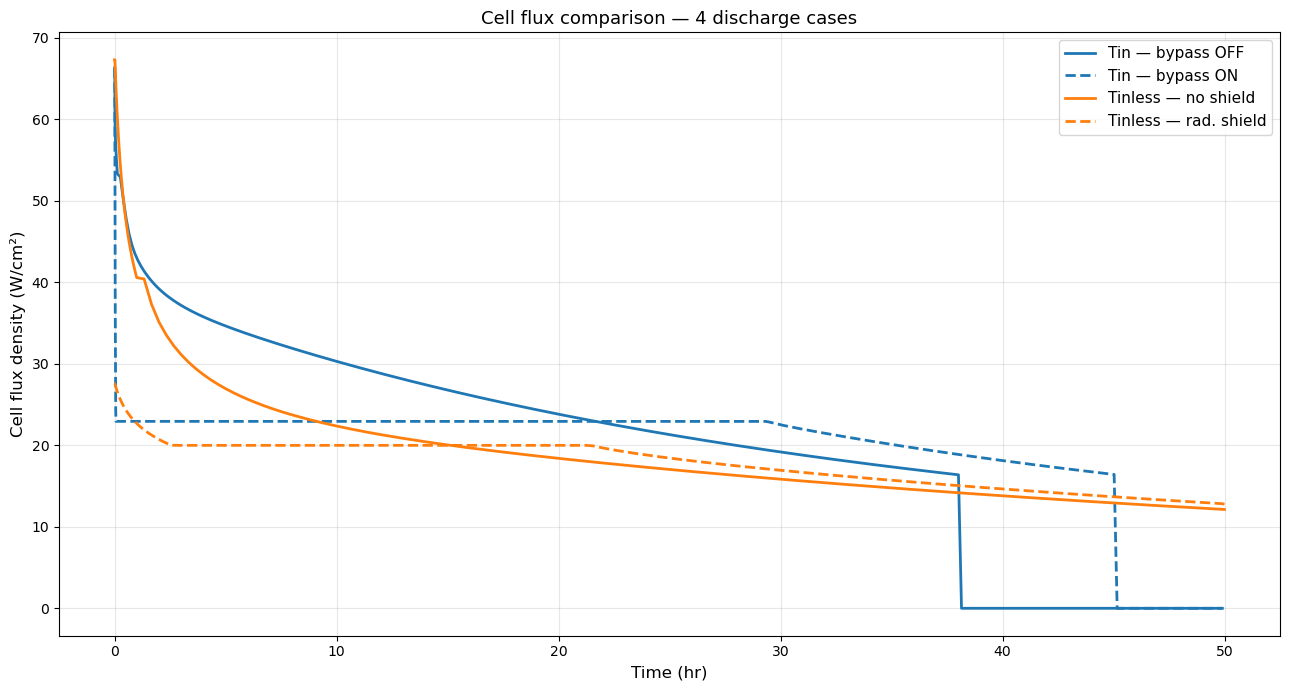

Saved cell_flux_comparison.png
Saved cell_flux_comparison.xlsx


In [32]:
import pandas as pd

fig, ax = plt.subplots(figsize=(13, 7))

# Tin system — blue; bypass OFF = solid, bypass ON = dashed
t1 = np.array(res_tin_bypass["time"]) / 3600
f1 = np.array(res_tin_bypass["cell_flux"]) / cell_area_cm2
t2 = np.array(res_tin_nobypass["time"]) / 3600
f2 = np.array(res_tin_nobypass["cell_flux"]) / cell_area_cm2
ax.plot(t2, f2, lw=2, color="tab:blue", label="Tin — bypass OFF")
ax.plot(t1, f1, lw=2, color="tab:blue", ls="--", label="Tin — bypass ON")

# Tinless system — orange; no shade = solid, with shade = dashed
t3 = res_tl_noshade["time"] / 3600
f3 = res_tl_noshade["Q_cell"] / cell_area_cm2
t4 = res_tl_shade["time"] / 3600
f4 = res_tl_shade["Q_cell"] / cell_area_cm2
ax.plot(t3, f3, lw=2, color="tab:orange", label="Tinless — no shade")
ax.plot(t4, f4, lw=2, color="tab:orange", ls="--", label="Tinless — rad. shade")

#ax.set_xscale("log")
ax.set_xlabel("Time (hr)", fontsize=12)
ax.set_ylabel("Cell flux density (W/cm²)", fontsize=12)
ax.set_title("Cell flux comparison — 4 discharge cases", fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("cell_flux_comparison.png", dpi=150)
plt.show()
print("Saved cell_flux_comparison.png")

# Save to Excel — each case on its own sheet
xlsx_path = "cell_flux_comparison.xlsx"
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    pd.DataFrame({"Time (hr)": t2, "Cell flux (W/cm2)": f2}).to_excel(
        writer, sheet_name="Tin bypass OFF", index=False)
    pd.DataFrame({"Time (hr)": t1, "Cell flux (W/cm2)": f1}).to_excel(
        writer, sheet_name="Tin bypass ON", index=False)
    pd.DataFrame({"Time (hr)": t3, "Cell flux (W/cm2)": f3}).to_excel(
        writer, sheet_name="Tinless no shade", index=False)
    pd.DataFrame({"Time (hr)": t4, "Cell flux (W/cm2)": f4}).to_excel(
        writer, sheet_name="Tinless rad shade", index=False)
print(f"Saved {xlsx_path}")
